<a href="https://colab.research.google.com/github/luminescent11/MTB-Detection/blob/main/MTB_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MTB Detection

### Summary:

### Table of Contents (linked)

[Data Preprocessing](#scrollTo=yPZylPHgKV_R&line=1&uniqifier=1) • [Creating the Baseline](#scrollTo=4Ev93LyYKagU&line=1&uniqifier=1) • [Training the Model](#scrollTo=845lKwpGKfut&line=1&uniqifier=1) • [Functions for Performance Metric Calculation](#scrollTo=Jl9KcJn8KkNq&line=1&uniqifier=1) • [Testing the baseline and both models](#scrollTo=-Tbmi3Ttp46a&line=1&uniqifier=1) • [Evaluating the model's metrics](#scrollTo=8n3FiqCqqBqT&line=1&uniqifier=1) • **[Showcase demo](#scrollTo=2bsP1F-UpqVF&line=1&uniqifier=1)** • [Failure examples](#scrollTo=PcmSRW6Vpgoq&line=1&uniqifier=1)

Imports and file paths

In [1]:
!pip install ultralytics==8.4.213
import ultralytics
from ultralytics import YOLO
from pathlib import Path
from google.colab import drive
import numpy as np
import torch
import yaml
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from ultralytics.utils.metrics import box_iou
drive.mount("/content/drive")
!unzip -o -q "/content/drive/MyDrive/MTB Detection/Raw_Sputum_Microscopy_Dataset.zip" -d /content/data
!ls /content/data

data_config_a = "/content/drive/MyDrive/MTB Detection/exp_a.yaml"
data_config_b = "/content/drive/MyDrive/MTB Detection/exp_b.yaml"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 64.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
images	labels


# Data Preprocessing

[Back to Top](#scrollTo=sDvyZU8wLCir&line=1&uniqifier=1)

Correcting a corrupted label that put 1 instead of 0 for the class (there is only one class in the dataset)

In [2]:
# Fix the one mislabeled training annotation (class 1 -> 0), then clear label caches.
# Runs every session, because unzipping restores the original file.
LABELS = Path('/content/data/labels')
bad_file = LABELS / 'train' / 'sputum_train_0853.txt'

lines = bad_file.read_text().splitlines()
fixed = [('0' + l[l.index(' '):]) if l.strip() and l.split()[0] == '1' else l
         for l in lines]
bad_file.write_text('\n'.join(fixed) + '\n')
print('changed lines:', sum(a != b for a, b in zip(lines, fixed)))

for cache in LABELS.glob('*.cache'):
    cache.unlink()
    print('deleted', cache)

changed lines: 1


Verifying no more corrupted labels (the list printed below should be empty)

In [3]:
bad = [p for p in Path('/content/data/labels').rglob('*.txt')
       if any(l.split()[0] != '0' for l in p.read_text().splitlines() if l.strip())]
print('files with a non-zero class:', bad)

files with a non-zero class: []


Creating data splits for both experiments

In [4]:
import pandas as pd
from pathlib import Path

DATA = Path('/content/data')                                      # unzipped images/labels (local)
SPLITS = Path('/content/splits')                                  # local folder for lists + YAMLs
META = Path('/content/drive/MyDrive/MTB Detection/metadata.csv')  # metadata on Drive (your path)
SPLITS.mkdir(parents=True, exist_ok=True)

# map image file stem -> full local path, for every image in images/train|val|test
files = {p.name: p for p in DATA.rglob('images/*/*')}

meta = pd.read_csv(META)
meta['stem'] = meta['Image_ID'].astype(str).map(lambda s: Path(s).stem)
meta['path'] = meta['Image_ID'].map(files)
meta['split'] = meta['Data_Split'].str.strip().str.lower()
meta['camera'] = meta['Camera_System'].str.strip().str.lower()

stems_on_disk = {}
for p in DATA.rglob('images/*/*'):
    stems_on_disk.setdefault(p.stem, []).append(p)
ambiguous = {s for s, v in stems_on_disk.items() if len(v) > 1}
print('excluded ambiguous stems by split:',
      meta[meta['stem'].isin(ambiguous)].groupby('split').size().to_dict())
meta = meta[~meta['stem'].isin(ambiguous)].reset_index(drop=True)

print('images on disk:', len(files), '| metadata rows:', len(meta),
      '| rows with no image:', meta['path'].isna().sum())

# sanity check: metadata split must match the folder the image sits in
mismatch = meta.dropna(subset=['path'])
mismatch = mismatch[mismatch['path'].map(lambda p: p.parent.name) != mismatch['split']]
print('split mismatches:', len(mismatch))

def write_list(df, name):
    paths = df['path'].dropna().astype(str).tolist()
    (SPLITS / f'{name}.txt').write_text('\n'.join(paths) + '\n')
    print(f'{name}: {len(paths)} images')

for split in ['train', 'val', 'test']:
    s = meta[meta['split'] == split]
    write_list(s, f'{split}_all')
    for cam in ['hayear', 'optilab']:
        write_list(s[s['camera'] == cam], f'{split}_{cam}')

excluded ambiguous stems by split: {'test': 17, 'train': 170, 'val': 25}
images on disk: 1650 | metadata rows: 1226 | rows with no image: 0
split mismatches: 0
train_all: 979 images
train_hayear: 494 images
train_optilab: 485 images
val_all: 117 images
val_hayear: 57 images
val_optilab: 60 images
test_all: 130 images
test_hayear: 67 images
test_optilab: 63 images


# Creating the baseline

[Back to Top](#scrollTo=sDvyZU8wLCir&line=1&uniqifier=1)

Median MTB count of A is 6

Median MTB count of B is 6

In [5]:
import yaml
import numpy as np

# Path(str(p).replace('/images/', '/labels/')).with_suffix('.txt')
# experiment A
a_box_counts = []

with open(data_config_a, "r") as file:
  loaded_config_a = yaml.safe_load(file)
  a_train_split_path = loaded_config_a["train"]

  with open(a_train_split_path, "r") as file2:
    list_of_labels_a = file2.read().strip().split('\n')

    for image_path in list_of_labels_a:
        path = Path(image_path.replace('/images/', '/labels/')).with_suffix('.txt')
        num_boxes = sum(1 for l in path.read_text().splitlines() if l.strip()) if path.exists() else 0
        a_box_counts.append(num_boxes)


# experiment B
b_box_counts = []

with open(data_config_b, "r") as file:
  loaded_config_b = yaml.safe_load(file)
  b_train_split_path = loaded_config_b["train"]


  with open(b_train_split_path, "r") as file2:
    list_of_labels_b = file2.read().strip().split('\n')

    for image_path in list_of_labels_b:
        path = Path(image_path.replace('/images/', '/labels/')).with_suffix('.txt')
        num_boxes = sum(1 for l in path.read_text().splitlines() if l.strip()) if path.exists() else 0
        b_box_counts.append(num_boxes)

# numbers
med_A, med_B = np.median(a_box_counts), np.median(b_box_counts)
print('baseline medians  A:', med_A, ' B:', med_B, '| images:', len(a_box_counts), len(b_box_counts))

baseline medians  A: 6.0  B: 6.0 | images: 979 494


# Training the Model

[Back to Top](#scrollTo=sDvyZU8wLCir&line=1&uniqifier=1)

Hyperparameters and settings

In [6]:
IMGSZ = 1280
EPOCHS = 100
PATIENCE = 20
BATCH = 8
RUNS = '/content/drive/MyDrive/MTB Detection/runs'   # Drive output folder
RUN_TRAINING = False
RUN_PREDICT = False

Experiment A training and validating

In [7]:
if RUN_TRAINING:
  model = YOLO('yolo26n.pt')
  model.train(
      data=data_config_a,
      imgsz=IMGSZ,
      epochs=EPOCHS,
      batch=BATCH,
      patience=PATIENCE,

      flipud=0.5, # augmentation since there is no sense of up in these top-down images

      project=RUNS, # directory where results are saved
      name='exp_a_clean', # subdirectory of RUNS where results are saved
      save_period=5
  )

  model.val(
      data=data_config_a,
      imgsz=IMGSZ,
      batch=BATCH,
      name='exp_a_clean',
      split='val',
      project=RUNS
  )
else:
  print('Skipped: exp_a already trained, weights already stored at ', f'{RUNS}/exp_a_clean/weights/')

# after a disconnect: rerun cells 1, 3, 5, 7, then run this line:
# YOLO(f'{RUNS}/exp_a_clean/weights/last.pt').train(resume=True)

Skipped: exp_a already trained, weights already stored at  /content/drive/MyDrive/MTB Detection/runs/exp_a_clean/weights/


Experiment B training and validating

In [8]:
if RUN_TRAINING:
  model = YOLO('yolo26n.pt')
  model.train(
      data=data_config_b,
      imgsz=IMGSZ,
      epochs=EPOCHS,
      batch=BATCH,
      patience=PATIENCE,

      flipud=0.5, # augmentation since there is no sense of up in these top-down images

      project=RUNS, # directory where results are saved
      name='exp_b_clean', # subdirectory of RUNS where results are saved
      save_period=5
  )

  model.val(
      data=data_config_b,
      imgsz=IMGSZ,
      batch=BATCH,
      name='exp_b_clean',
      split='val',
      project=RUNS
  )
else:
  print('Skipped: exp_b_clean already trained, weights already stored at ', f'{RUNS}/exp_b_clean/weights/')

# after a disconnect: rerun cells 1, 3, 5, and 7, then run this line:
# YOLO(f'{RUNS}/exp_b_clean/weights/last.pt').train(resume=True)

Skipped: exp_b_clean already trained, weights already stored at  /content/drive/MyDrive/MTB Detection/runs/exp_b_clean/weights/


# Functions for Performance Metric Calculation

[Back to Top](#scrollTo=sDvyZU8wLCir&line=1&uniqifier=1)

Utility helper for retrieving paths based on split and camera

In [9]:
def get_label_paths(split, hayear=False, optilab=False):
  if not hayear and not optilab:
    raise ValueError("select a camera(s)")
  elif hayear and optilab:
    image_paths = meta[(meta.split == split)]['path']
  elif hayear:
    image_paths = meta[(meta.split == split) & (meta.camera == 'hayear')]['path']
  elif optilab:
    image_paths = meta[(meta.split == split) & (meta.camera == 'optilab')]['path']

  return [Path(str(image_path).replace('/images/', '/labels/')).with_suffix('.txt') for image_path in image_paths]

Helper for counting ground truth bacilli in an image

In [10]:
def count_true(p):
    lp = Path(str(p).replace('/images/', '/labels/')).with_suffix('.txt')
    return sum(1 for l in lp.read_text().splitlines() if l.strip()) if lp.exists() else 0

Creating the MAE baseline function for measuring error

In [11]:
def calculate_baseline_MAE(label_paths, prediction):
  box_counts = []
  for p in label_paths:
    box_counts.append(sum(1 for l in p.read_text().splitlines() if l.strip()) if p.exists() else 0)

  total_error = 0
  n = len(label_paths)

  for count in box_counts:
    total_error += abs(prediction-count)

  return total_error/n

Creating the MAE model function for measuring error

In [12]:
def calculate_model_MAE(image_paths, preds, cutoff): # confidence threshold
  errors = []

  for image_path in image_paths:
    _, conf, _ = preds[str(image_path)]

    pred_n = int((conf >= cutoff).sum())
    label_path = Path(str(image_path).replace('/images/', '/labels/')).with_suffix('.txt')

    true_n = sum(1 for l in label_path.read_text().splitlines() if l.strip()) if label_path.exists() else 0
    errors.append(abs(pred_n-true_n))

  return sum(errors) / len(errors)

Creating FP, FN, and TP counter function as well as a gt_boxes helper

In [13]:
from ultralytics.utils.metrics import box_iou

def gt_boxes(image_path, h, w):
    """True boxes for one image, converted from normalized YOLO (xc, yc, bw, bh) to pixel corners."""
    lp = Path(str(image_path).replace('/images/', '/labels/')).with_suffix('.txt')
    rows = [list(map(float, l.split()[1:5])) for l in lp.read_text().splitlines() if l.strip()] if lp.exists() else []
    if not rows:
        return torch.zeros((0, 4))
    xc, yc, bw, bh = torch.tensor(rows).T
    return torch.stack([(xc - bw/2) * w, (yc - bh/2) * h, (xc + bw/2) * w, (yc + bh/2) * h], 1)

def calculate_tp_fp_fn(image_paths, preds, cutoff, iou_thr=0.5):
    """Greedy matching at IoU >= iou_thr, using boxes with confidence >= cutoff."""
    tp = fp = fn = 0
    for image_path in image_paths:
        xyxy, conf, (h, w) = preds[str(image_path)]
        keep = conf >= cutoff
        pb = xyxy[keep][conf[keep].argsort(descending=True)]   # most confident first
        gt = gt_boxes(image_path, h, w)
        matched = 0
        if len(pb) and len(gt):
            iou = box_iou(pb, gt)                               # [num_pred, num_true]
            for i in range(len(pb)):
                j = int(iou[i].argmax())
                if iou[i, j] >= iou_thr:
                    matched += 1
                    iou[:, j] = 0                               # each true box matched once
        tp += matched
        fp += len(pb) - matched
        fn += len(gt) - matched
    return dict(TP=tp, FP=fp, FN=fn,
                precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1))

# Testing the baseline and both models

[Back to Top](#scrollTo=sDvyZU8wLCir&line=1&uniqifier=1)

Testing the baseline - the median counts/baseline constant for both experiments are the same, so we can test this baseline on each camera system individually and then the whole test set.

In [14]:
baseline_MAE_hayear = calculate_baseline_MAE(get_label_paths('test', True, False), med_A)
baseline_MAE_optilab = calculate_baseline_MAE(get_label_paths('test', False, True), med_A)
baseline_MAE_all = calculate_baseline_MAE(get_label_paths('test', True, True), med_A)

print(f"Hayear baseline MAE is {baseline_MAE_hayear}")
print(f"Optilab baseline MAE is {baseline_MAE_optilab}")
print(f"Overall baseline MAE is {baseline_MAE_all}")

Hayear baseline MAE is 5.253731343283582
Optilab baseline MAE is 5.031746031746032
Overall baseline MAE is 5.1461538461538465


Testing the model

In [15]:
if RUN_PREDICT:
  def predict_all(weights, image_paths):
    m, out = YOLO(weights), {}
    for p in image_paths:
        r = m.predict(str(p), imgsz=IMGSZ, conf=0.01, max_det=1000, verbose=False)[0]
        out[r.path] = (r.boxes.xyxy.cpu(), r.boxes.conf.cpu(), r.orig_shape)
        del r
    del m
    torch.cuda.empty_cache()
    return out

  val_all    = meta[meta.split == 'val']['path']
  val_hayear = meta[(meta.split == 'val') & (meta.camera == 'hayear')]['path']
  test_all   = meta[meta.split == 'test']['path']          # both cameras; split later with meta

  pA = predict_all(f'{RUNS}/exp_a_clean/weights/best.pt', list(val_all) + list(test_all))
  pB = predict_all(f'{RUNS}/exp_b_clean/weights/best.pt', list(val_hayear) + list(test_all))
  print(len(pA), len(pB))

  torch.save({'pA': pA, 'pB': pB}, f'{RUNS}/preds.pt')
else:
  print('Skipped: predictions already done, outputs already stored at ', f'{RUNS}/preds.pt')

Skipped: predictions already done, outputs already stored at  /content/drive/MyDrive/MTB Detection/runs/preds.pt


# Evaluating the model's metrics

[Back to Top](#scrollTo=sDvyZU8wLCir&line=1&uniqifier=1)

Reload cell - loading the dataset splits and predictions for analyzing results. The model itself is not loaded because testing has already been done.

In [16]:
val_all    = meta[meta.split == 'val']['path']
val_hayear = meta[(meta.split == 'val') & (meta.camera == 'hayear')]['path']
test_all   = meta[meta.split == 'test']['path']          # both cameras; split later with meta

d = torch.load(f'{RUNS}/preds.pt', weights_only=False)
pA, pB = d['pA'], d['pB']
print(len(pA), len(pB))

247 187


Determining a confidence threshold for each of the tested models by iterating over 0.05, 0.06, ... 0.89, 0.90 and choosing the one with the lowest val MAE.

In [17]:
conf_cutoffs = np.round(np.arange(0.05, 0.91, 0.01), 2)

cA = conf_cutoffs[np.argmin([calculate_model_MAE(val_all, pA, c) for c in conf_cutoffs])]
cB = conf_cutoffs[np.argmin([calculate_model_MAE(val_hayear, pB, c) for c in conf_cutoffs])]

print('determined confidence cutoffs: A', cA, ' | ', 'B ', cB)

determined confidence cutoffs: A 0.34  |  B  0.3


Result metrics

In [18]:
subsets = {
    'hayear':  meta[(meta.split == 'test') & (meta.camera == 'hayear')]['path'],
    'optilab': meta[(meta.split == 'test') & (meta.camera == 'optilab')]['path'],
    'overall': meta[meta.split == 'test']['path'],
}
models = {'A': (pA, cA), 'B': (pB, cB)}

results = {}                                   # camera -> experiment -> metric
for cam, imgs in subsets.items():
    labels = [Path(str(p).replace('/images/', '/labels/')).with_suffix('.txt') for p in imgs]
    base = calculate_baseline_MAE(labels, med_A)
    results[cam] = {'baseline': {'MAE': base}}
    for name, (preds, cut) in models.items():
        mae = calculate_model_MAE(imgs, preds, cut)
        m = calculate_tp_fp_fn(imgs, preds, cut)
        f1 = 2 * m['precision'] * m['recall'] / max(m['precision'] + m['recall'], 1e-9)
        results[cam][name] = {'MAE': mae, 'vs_baseline_%': 100 * (base - mae) / base,
                              'precision': m['precision'], 'recall': m['recall'], 'F1': f1,
                              'FN': m['FN'], 'FP': m['FP'], 'TP': m['TP']}

table = pd.DataFrame([{'camera': c, 'experiment': e, **v}
                      for c, exps in results.items() for e, v in exps.items()]).round(3)
table.to_csv(f'{RUNS}/test_results.csv', index=False)
table

,camera,experiment,MAE,vs_baseline_%,precision,recall,F1,FN,FP,TP
0,hayear,baseline,5.254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,hayear,A,1.866,64.489,0.772,0.717,0.743,170.0,127.0,430.0
2,hayear,B,1.985,62.216,0.743,0.727,0.735,164.0,151.0,436.0
3,optilab,baseline,5.032,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,optilab,A,1.444,71.293,0.799,0.723,0.759,137.0,90.0,358.0
5,optilab,B,1.444,71.293,0.755,0.717,0.736,140.0,115.0,355.0
6,overall,baseline,5.146,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,overall,A,1.662,67.713,0.784,0.720,0.750,307.0,217.0,788.0
8,overall,B,1.723,66.517,0.748,0.722,0.735,304.0,266.0,791.0


Examining empty fields - does the model report false positives?

In [19]:
def is_empty(p):
    lp = Path(str(p).replace('/images/', '/labels/')).with_suffix('.txt')
    return not lp.exists() or not any(l.strip() for l in lp.read_text().splitlines())

for cam in ['hayear', 'optilab']:
    empty = [p for p in subsets[cam] if is_empty(p)]
    print(cam, f'(n={len(empty)} empty fields)',
          '| A false alarms:', calculate_tp_fp_fn(empty, pA, cA)['FP'],
          '| B false alarms:', calculate_tp_fp_fn(empty, pB, cB)['FP'])

hayear (n=3 empty fields) | A false alarms: 2 | B false alarms: 1
optilab (n=2 empty fields) | A false alarms: 0 | B false alarms: 0


# Showcase demo

[Back to Top](#scrollTo=sDvyZU8wLCir&line=1&uniqifier=1)

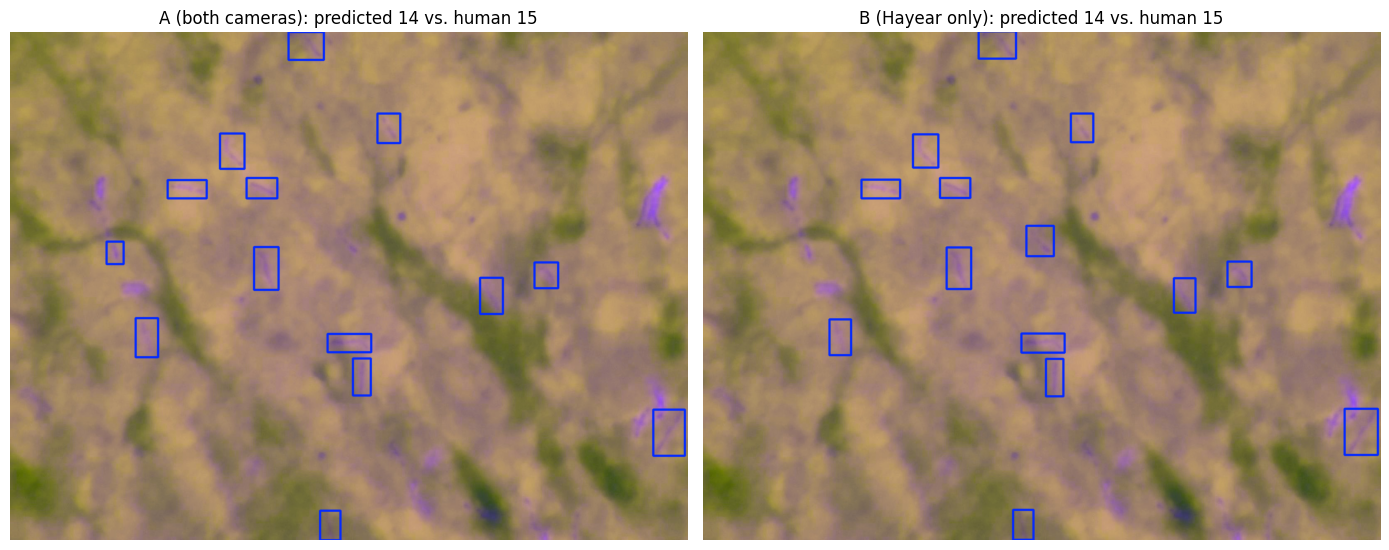

In [20]:
import matplotlib.pyplot as plt

opt = list(subsets['optilab'])
img = str(opt[len(opt) // 2])            # a middle image, not cherry-picked; say so in the caption

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, w, cut) in zip(axes, [('A (both cameras)', 'exp_a_clean', cA),
                                     ('B (Hayear only)',  'exp_b_clean', cB)]):
    r = YOLO(f'{RUNS}/{w}/weights/best.pt').predict(img, imgsz=IMGSZ, conf=cut,
                                                    max_det=1000, verbose=False)[0]
    ax.imshow(r.plot(labels=False, conf=False)[..., ::-1])
    ax.set_title(f'{name}: predicted {len(r.boxes)} vs. human {count_true(img)}')
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{RUNS}/showcase.png', dpi=150, bbox_inches='tight')
plt.show()

# Failure examples

[Back to Top](#scrollTo=sDvyZU8wLCir&line=1&uniqifier=1)

Worst 3 errors from B on Optilab (the camera it did not train or validate on)

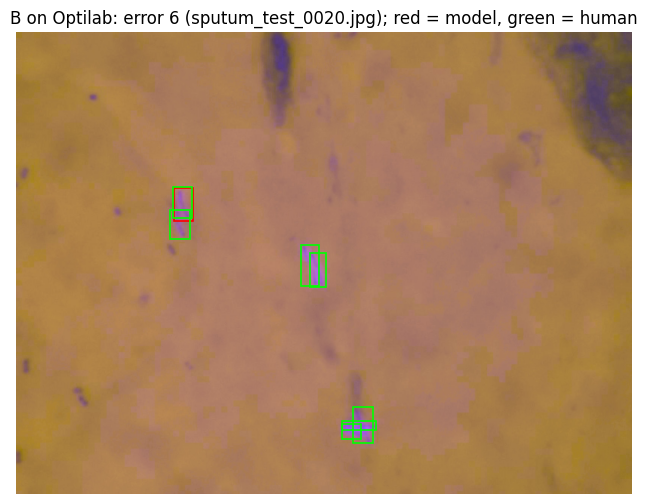

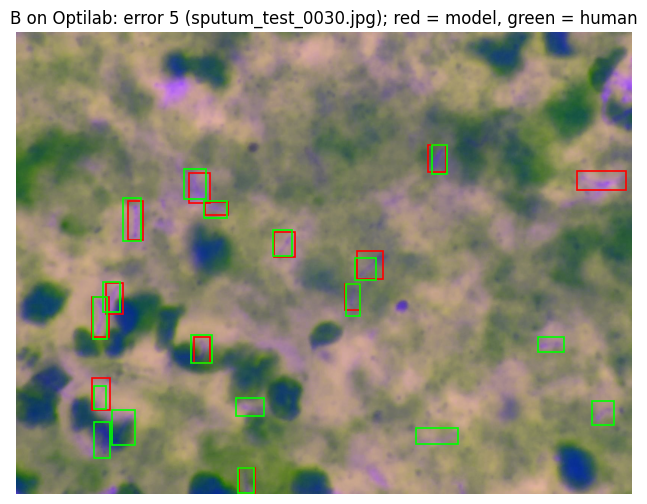

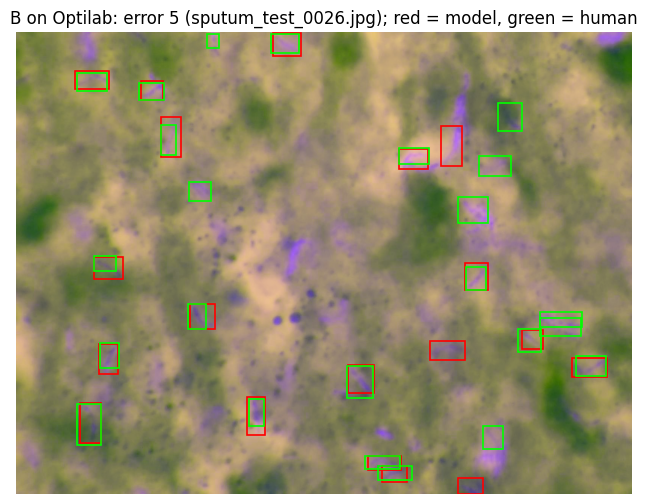

In [21]:
errs = sorted(((abs(int((pB[str(p)][1] >= cB).sum()) - count_true(p)), str(p))
               for p in subsets['optilab']), reverse=True)[:3]
for e, p in errs:
    xyxy, conf, (h, w) = pB[p]
    im = plt.imread(p)
    plt.figure(figsize=(8, 6)); plt.imshow(im); plt.axis('off')
    for b in xyxy[conf >= cB]:                     # model boxes: red
        plt.gca().add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec='red', lw=1.2))
    for b in gt_boxes(p, h, w):                     # true boxes: green
        plt.gca().add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec='lime', lw=1.2))
    plt.title(f'B on Optilab: error {e} ({Path(p).name}); red = model, green = human')
    plt.savefig(f'{RUNS}/failure_{Path(p).stem}.png', dpi=150, bbox_inches='tight'); plt.show()